In [1]:
import sys
import os
import matplotlib.pyplot as plt
import matplotlib.pyplot as plt
import numpy as np
import torch
import random

In [2]:
# set seeds 
np.random.seed(1)
torch.manual_seed(1)
random.seed(1)

In [3]:
def read_parameters(file_path):
    params = {}

    # First pass: read and store values as strings
    with open(file_path, 'r') as file:
        for line in file:
            # Skip empty lines and comments (if any)
            line = line.strip()
            if line and not line.startswith('#'):
                # Split the line at the equals sign
                key, value = line.split('=')
                key = key.strip()
                value = value.strip()

                # Store the parameter as a string for now
                params[key] = value

    # Second pass: evaluate expressions and convert values
    for key, value in params.items():
        try:
            # Try to evaluate the value as a Python expression using previously defined parameters
            params[key] = eval(value, {}, params)
        except:
            # If it's not an expression, check if it can be converted to float or int
            if '.' in value:
                params[key] = float(value)
            else:
                params[key] = int(value)
        
        # Set the variable in the global namespace with the evaluated value
        globals()[key] = params[key]

    return params

In [4]:
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), "..")))
from ants_move import *
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), "../..")))
from ddqn.buffer import *

pygame 2.6.0 (SDL 2.28.4, Python 3.8.2)
Hello from the pygame community. https://www.pygame.org/contribute.html


In [5]:
work_folder = 'federated'
saving_folder = 'prova'
os.chdir(work_folder)

In [6]:
file_path = saving_folder + '/parameters.txt'  # Path to the parameters file
parameters = read_parameters(file_path)

for key, value in parameters.items():
    print(f"{key} = {value}")

n = 150
Lx = 32
Ly = 32
delta = 0.3
beta = 4.5
eta = 0.07
decay_rate = 0.015
eta_special = 0.07
n_special = 150
t_transient = 0
tmax = 1000
batch_size = 64
gamma = 0.99
max_size = 10000000
state_dim = (3, 5, 5)
action_dim = 8
action_bound = 1
critic_lr = 1e-05
tau = 0.001
noise = 0.05
weight_decay = 0.01
epsilon_decay = 0.99999
epsilon_min = 0.01
target_upd_steps = 20
epsilon_start = 1


In [7]:
env = Ants(n, Lx, Ly, delta, beta, decay_rate, eta, eta_special,
                  tmax, n_special, t_transient, vision=state_dim[-1])

buffer = ReplayBuffer(max_size, state_dim, action_dim)

In [8]:
from ddqn_ants import *
config_net_file = f"{saving_folder}/networks.yaml"
ddqn_ants = DDQN_ants(env, buffer,
                 gamma, action_bound, critic_lr, tau, batch_size, epsilon_decay, weight_decay, config_net_file,
                 target_upd_steps, epsilon_min, epsilon_start)
        

In [9]:
load_from_run = False
ddqn_ants.setup_networks()

if load_from_run:
    ddqn_ants.load_weights(saving_folder + '/weights')
else:
    ddqn_ants.critic.load_state_dict(torch.load(f"{saving_folder}/weights.pth", weights_only=True))

/home/apitteri/.local/lib/python3.8/site-packages/torch/nn/modules/conv.py:454: UserWarning: Using padding='same' with even kernel lengths and odd dilation may require a zero-padded copy of the input be created (Triggered internally at ../aten/src/ATen/native/Convolution.cpp:1031.)
  return F.conv2d(input, weight, bias, self.stride,


In [10]:
save_model = False

if save_model:
    torch.save(ddqn_ants.critic.state_dict(), f"{saving_folder}/weights.pth")

In [11]:
ddqn_ants.epsilon = epsilon_min

In [12]:
env.reset_objects()
env.transient()

trans_pos = env.positions.copy()
trans_pher = env.pheromones.copy()

results = ddqn_ants.test_episode(explore = True, return_pos=True)

In [13]:
print(np.mean(results[0]))

0.7386266666666667


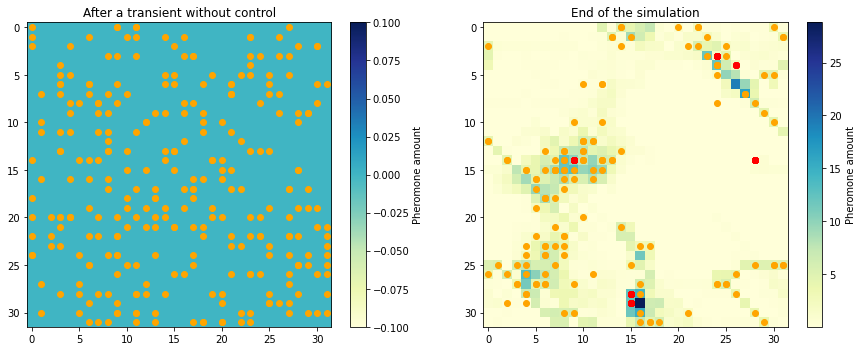

In [14]:
import matplotlib.pyplot as plt
import numpy as np

fig, ax = plt.subplots(1,2,figsize=(15, 8))

im1 = ax[0].imshow(trans_pher.T, cmap='YlGnBu')
ax[0].scatter(np.array(trans_pos)[:-10,0],np.array(trans_pos)[:-10,1], c='orange')
ax[0].set_title('After a transient without control')
cbar1 = plt.colorbar(im1, ax=ax[0], shrink=0.7)
cbar1.set_label('Pheromone amount')

im2 = ax[1].imshow(env.pheromones.T, cmap='YlGnBu')
ax[1].scatter(np.array(env.positions)[:env.n,0],np.array(env.positions)[:env.n,1], c='orange')
ax[1].scatter(np.array(env.positions)[env.n:,0],np.array(env.positions)[env.n:,1], c='red')
#ax[1].scatter(np.array(env.positions)[-10:,0],np.array(env.positions)[-10:,1], c='black', marker='x')
ax[1].set_title('End of the simulation')

cbar2 = plt.colorbar(im2, ax=ax[1], shrink=0.7)
cbar2.set_label('Pheromone amount')

plt.savefig('trails.pdf')
plt.show()

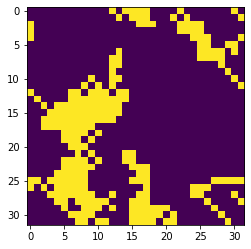

In [15]:
plt.imshow(env.pheromones.T>env.s0)

In [16]:
s = np.array([np.diag((1,1,1,1,1)), np.diag((0,0,0,0,0)), np.diag((10,10,10,10,10))]).reshape(1,3,5,5)

In [17]:
rewards = np.array(results[0])
actions = np.array(results[1])
states = np.array(results[2])
pos = np.array(results[3])

In [18]:
pos_list = pos
pher_list = np.zeros((32,32))

In [19]:
np.unique(actions)

array([0, 1, 2, 3, 4, 5, 6, 7])

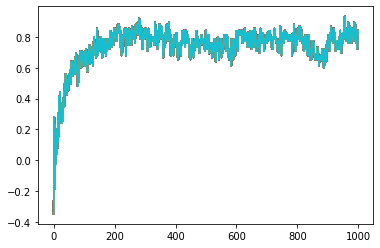

In [20]:
plt.plot(rewards)
plt.show()

In [21]:
env.order_parameter_p()

0.8266666666666667

In [22]:
pos.shape

(1001, 300, 2)

In [23]:
running = True

# create env
env.reset_objects()
pygame.init()

# set the color of the background
background_color = (255, 255, 255) 

# create the screen
screen_x, screen_y = 1000, 1000
screen_scale = screen_x/Lx

screen = pygame.display.set_mode((screen_x, screen_y)) 

# set the frame rate
FPS = 60
clock = pygame.time.Clock()

t = 0   

while running:
    for event in pygame.event.get():
        if event.type == pygame.QUIT:
            running = False
    
    # display env 
    screen.fill(background_color)

    for i in range(env.num):
            
        if i < env.n:
            pygame.draw.circle(screen, (0, 0, 0), 
                                (pos[t,i,0]*screen_scale, pos[t,i,1]*screen_scale), 3)
        if i > env.n:
            pygame.draw.circle(screen, (255, 0, 0), 
                                (pos[t,i,0]*screen_scale, pos[t,i,1]*screen_scale), 10)

    # update counter
    t += 1

    if t == (tmax-t_transient):
        running = False

    # env.pheromones[env.t%Lx, env.t%Ly] += power*amount[0]

    # update display
    pygame.display.flip()
    # limit the frame rate
    clock.tick(FPS)

    print(t, end='\r')
    
pygame.quit()

(array([11675., 22514., 26172., 13016.,  8853., 36847., 13182., 17741.]),
 array([0, 1, 2, 3, 4, 5, 6, 7, 8]),
 <BarContainer object of 8 artists>)

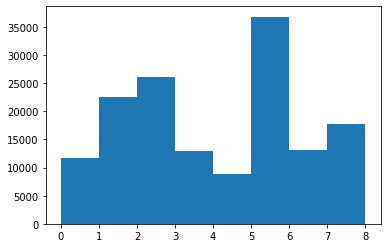

In [24]:
plt.hist(actions.flatten(), bins=np.arange(9))

(array([ 8125., 10826., 27249., 38268., 28155.,  8176.,  3048.,  4842.,
         7367., 14094.]),
 array([   0. ,  102.3,  204.6,  306.9,  409.2,  511.5,  613.8,  716.1,
         818.4,  920.7, 1023. ]),
 <BarContainer object of 10 artists>)

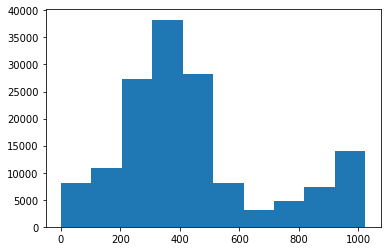

In [25]:
plt.hist( (pos[:,env.n:,0]*Ly+pos[:,env.n:,1]).flatten() )

In [26]:
trial_states = np.random.uniform(0,20,(1000,3,3,3))
trial_actions = ddqn_ants.policy(trial_states, explore=False)

RuntimeError: mat1 and mat2 shapes cannot be multiplied (1000x576 and 1600x128)

In [ ]:
plt.hist(trial_actions, bins=np.arange(0,9))

In [ ]:
# critic evaluation
vision = 3
value_list = []
best_action_list = []
for i in range(env.Lx):
    for j in range(env.Ly):
        state = env.gauss[ddqn_ants.meshgrid(i, j)].reshape(1, vision, vision)
        v = ddqn_ants.critic(torch.tensor(state, dtype=torch.float32).unsqueeze(0)).detach().numpy()
        value_list.append(np.max(v))
        best_action_list.append(np.argmax(v))

directions = env.directions
field = directions[best_action_list]

In [ ]:
value_grid = np.array(value_list).reshape(env.Lx, env.Ly)
field = np.array(field).reshape(env.Lx, env.Ly, 2)

# Extract coordinates
X, Y = np.meshgrid(np.arange(env.Lx), np.arange(env.Ly))  # Grid positions
U, V = field[:, :, 0], field[:, :, 1]  # Vector components

# Plot the quiver plot
plt.figure(figsize=(8,6))
plt.quiver(X, Y, V, U, value_grid,  angles='xy', scale_units='xy', scale=2, cmap='viridis')
plt.colorbar(label="Value Function")
plt.xlabel("X")
plt.ylabel("Y")
plt.title("Vector Field of Best Actions")
plt.gca().invert_yaxis()  # Invert y-axis to match matrix indexing
plt.show()